In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms, datasets, utils
from torch.utils.data import DataLoader
import torchvision.utils as vutils

import matplotlib.pyplot as plt
import numpy as np
import math
import os
from glob import glob

In [2]:
transform = transforms.Compose([
    transforms.Resize((32, 32)),             # Match model input
    transforms.ToTensor(),                   # Convert to tensor [0, 1]
    transforms.Lambda(lambda x: x * 2 - 1),  # Normalize to [-1, 1]
])

# Automatically downloads and loads MNIST
dataset = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
dataloader = DataLoader(dataset, batch_size=64, shuffle=True, num_workers=2)

# Text label mapping
label_to_text = ["zero", "one", "two", "three", "four", "five", "six", "seven", "eight", "nine"]


100%|██████████| 9.91M/9.91M [00:00<00:00, 52.5MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.74MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 14.8MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.91MB/s]


In [3]:
## Training Parameters
T = 1000  # diffusion steps
beta_start, beta_end = 1e-4, 0.02
betas = torch.linspace(beta_start, beta_end, T)
alphas = 1 - betas
alphas_cumprod = torch.cumprod(alphas, dim=0)

def get_noise_schedule(t):
    return alphas_cumprod[t], betas[t]

def q_sample(x_start, t, noise=None):
    if noise is None:
        noise = torch.randn_like(x_start)
    
    # Move to same device as input t
    device = t.device
    sqrt_alpha_cumprod = torch.sqrt(alphas_cumprod.to(device)[t])[:, None, None, None]
    sqrt_one_minus = torch.sqrt(1 - alphas_cumprod.to(device)[t])[:, None, None, None]

    return sqrt_alpha_cumprod * x_start + sqrt_one_minus * noise


In [4]:
class TextEmbedding(nn.Module):
    def __init__(self, vocab_size=10, emb_dim=128):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim)

    def forward(self, labels):
        return self.embedding(labels)


In [5]:
# --- Sinusoidal Time Embedding ---
class TimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        """
        t: a tensor of shape [batch_size] containing integer timestep indices
        Returns a tensor of shape [batch_size, dim] representing sinusoidal embeddings.
        """
        half_dim = self.dim // 2
        emb_scale = math.log(10000) / (half_dim - 1)
        emb = torch.exp(torch.arange(half_dim, device=t.device) * -emb_scale)
        emb = t[:, None] * emb[None, :]  # shape: [batch_size, half_dim]
        emb = torch.cat((emb.sin(), emb.cos()), dim=1)  # shape: [batch_size, dim]
        return emb

# --- Residual Block with Time Conditioning ---
class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch, time_emb_dim):
        super().__init__()
        # First convolutional layer (in_ch → out_ch)
        self.block1 = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1),
            nn.GroupNorm(num_groups=4, num_channels=out_ch),
            nn.SELU(inplace=True)
        )
        # Linear layer to project time embedding to channel dimension
        self.time_proj = nn.Linear(time_emb_dim, out_ch)
        # Second convolutional layer (out_ch → out_ch)
        self.block2 = nn.Sequential(
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1),
            nn.GroupNorm(num_groups=4, num_channels=out_ch),
            nn.SELU(inplace=True)
        )
        # Skip connection: if in_ch ≠ out_ch, use 1×1 conv to match dimensions
        self.skip = nn.Conv2d(in_ch, out_ch, kernel_size=1) if in_ch != out_ch else nn.Identity()

    def forward(self, x, t_emb):
        """
        x: tensor of shape [batch_size, in_ch, H, W]
        t_emb: tensor of shape [batch_size, time_emb_dim]
        """
        h = self.block1(x)  # shape: [B, out_ch, H, W]
        # Project time embedding and add to feature map
        t_proj = self.time_proj(t_emb).view(t_emb.size(0), -1, 1, 1)
        h = h + t_proj
        h = self.block2(h)  # shape: [B, out_ch, H, W]
        return h + self.skip(x)  # residual connection

# --- Self-Attention Block (Optional) ---
class SelfAttentionBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.norm = nn.GroupNorm(num_groups=8, num_channels=channels)
        self.qkv = nn.Conv2d(channels, channels * 3, kernel_size=1)
        self.proj = nn.Conv2d(channels, channels, kernel_size=1)

    def forward(self, x):
        """
        x: tensor of shape [batch_size, channels, H, W]
        Returns: tensor of same shape, with self-attention applied.
        """
        B, C, H, W = x.shape
        x_norm = self.norm(x)  # shape: [B, C, H, W]
        # Compute queries, keys, values
        q, k, v = self.qkv(x_norm).chunk(3, dim=1)  # each [B, C, H, W]

        # Reshape for attention
        q = q.reshape(B, C, H * W).permute(0, 2, 1)  # [B, HW, C]
        k = k.reshape(B, C, H * W)                   # [B, C, HW]
        v = v.reshape(B, C, H * W).permute(0, 2, 1)  # [B, HW, C]

        # Compute attention scores
        attn_scores = torch.bmm(q, k) / math.sqrt(C)  # [B, HW, HW]
        attn = torch.softmax(attn_scores, dim=-1)     # [B, HW, HW]

        # Weighted sum of values
        out = torch.bmm(attn, v).permute(0, 2, 1).reshape(B, C, H, W)  # [B, C, H, W]
        return x + self.proj(out)  # Add residual

# --- Downsampling Block ---
class Down(nn.Module):
    def __init__(self, in_ch, out_ch, time_emb_dim, use_attention=False):
        super().__init__()
        self.res = ResBlock(in_ch, out_ch, time_emb_dim)
        self.attn = SelfAttentionBlock(out_ch) if use_attention else nn.Identity()
        self.pool = nn.MaxPool2d(kernel_size=2)

    def forward(self, x, t_emb):
        """
        x: [B, in_ch, H, W]
        t_emb: [B, time_emb_dim]
        Returns: (pooled, skip) where
          pooled: [B, out_ch, H/2, W/2]
          skip:   [B, out_ch, H, W]
        """
        x = self.res(x, t_emb)  # [B, out_ch, H, W]
        x = self.attn(x)        # [B, out_ch, H, W]
        return self.pool(x), x  # pooled: [B, out_ch, H/2, W/2], skip: [B, out_ch, H, W]

# --- Upsampling Block ---
class Up(nn.Module):
    def __init__(self, x_ch, skip_ch, out_ch, time_emb_dim, use_attention=False):
        super().__init__()
        self.up = nn.Upsample(scale_factor=2, mode='nearest')
        self.res = ResBlock(x_ch + skip_ch, out_ch, time_emb_dim)
        self.attn = SelfAttentionBlock(out_ch) if use_attention else nn.Identity()

    def forward(self, x, skip, t_emb):
        """
        x: [B, x_ch, H, W]         (currently at lower resolution)
        skip: [B, skip_ch, H*2, W*2] (skip connection from encoder)
        t_emb: [B, time_emb_dim]
        """
        x = self.up(x)                     # [B, x_ch, H*2, W*2]
        x = torch.cat([x, skip], dim=1)    # [B, x_ch + skip_ch, H*2, W*2]
        x = self.res(x, t_emb)             # [B, out_ch, H*2, W*2]
        return self.attn(x)                # [B, out_ch, H*2, W*2]

# --- Bottleneck Block (Middle of U-Net) ---
class MidBlock(nn.Module):
    def __init__(self, ch, time_emb_dim):
        super().__init__()
        self.block1 = ResBlock(ch, ch, time_emb_dim)
        self.attn = SelfAttentionBlock(ch)
        self.block2 = ResBlock(ch, ch, time_emb_dim)

    def forward(self, x, t_emb):
        """
        x: [B, ch, H, W]
        t_emb: [B, time_emb_dim]
        """
        x = self.block1(x, t_emb)  # [B, ch, H, W]
        x = self.attn(x)           # [B, ch, H, W]
        x = self.block2(x, t_emb)  # [B, ch, H, W]
        return x


In [6]:
class ImprovedUNet(nn.Module):
    def __init__(self, in_channels=1, out_channels=1, time_emb_dim=128):
        super().__init__()
        self.time_mlp = nn.Sequential(
            TimeEmbedding(time_emb_dim),
            nn.Linear(time_emb_dim, time_emb_dim),
            nn.SELU(inplace=True)
        )
        self.text_mlp = nn.Sequential(
            nn.Linear(time_emb_dim, time_emb_dim),
            nn.SELU(inplace=True)
        )

        self.in_conv = nn.Conv2d(in_channels, 64, 3, padding=1)
        self.down1 = Down(64, 128, time_emb_dim)
        self.down2 = Down(128, 256, time_emb_dim, use_attention=True)
        self.mid = MidBlock(256, time_emb_dim)
        self.up1 = Up(256, 256, 128, time_emb_dim, use_attention=True)
        self.up2 = Up(128, 128, 64, time_emb_dim)
        self.out_conv = nn.Conv2d(64, out_channels, 1)

    def forward(self, x, t, text_emb=None):
        t_emb = self.time_mlp(t)
        if text_emb is not None:
            text_emb = self.text_mlp(text_emb)
            t_emb = t_emb + text_emb

        x1 = self.in_conv(x)
        x2, skip1 = self.down1(x1, t_emb)
        x3, skip2 = self.down2(x2, t_emb)
        x_mid = self.mid(x3, t_emb)
        x = self.up1(x_mid, skip2, t_emb)
        x = self.up2(x, skip1, t_emb)
        return self.out_conv(x)


In [7]:
os.makedirs("/kaggle/working/generated", exist_ok=True)

def reverse_sample(model, n_samples=8, img_size=32):
    model.eval()
    with torch.no_grad():
        x = torch.randn((n_samples, 1, img_size, img_size)).to(device)
        for t in reversed(range(T)):
            t_tensor = torch.full((n_samples,), t, device=device, dtype=torch.long)
            predicted_noise = model(x, t_tensor)

            alpha = alphas[t].to(device)
            alpha_bar = alphas_cumprod[t].to(device)
            beta = betas[t].to(device)

            x = (1 / torch.sqrt(alpha)) * (x - (1 - alpha) / torch.sqrt(1 - alpha_bar) * predicted_noise)

            if t > 0:
                z = torch.randn_like(x)
                x += torch.sqrt(beta) * z

        x = torch.clamp((x + 1) / 2, 0, 1)  # de-normalize to [0,1]
    model.train()
    return x

In [8]:
device = "cuda" if torch.cuda.is_available() else "cpu"
model = ImprovedUNet().to(device)
text_embedder = TextEmbedding().to(device)
optimizer = torch.optim.Adam(list(model.parameters()) + list(text_embedder.parameters()), lr=2e-4)

In [9]:
import os
os.makedirs("/kaggle/working/generated", exist_ok=True)
os.makedirs("/kaggle/working/checkpoints", exist_ok=True)

epochs = 200
best_loss = float("inf")  # Initialize best loss

for epoch in range(epochs):
    model.train()
    for x, labels in dataloader:
        x = x.to(device)
        labels = labels.to(device)

        t = torch.randint(0, T, (x.size(0),), device=device).long()
        noise = torch.randn_like(x)
        x_noisy = q_sample(x, t, noise)

        text_emb = text_embedder(labels)
        pred_noise = model(x_noisy, t, text_emb)

        loss = F.mse_loss(pred_noise, noise)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch+1}: Loss = {loss.item():.4f}")

    # Save model if it's the best so far
    if loss.item() < best_loss:
        best_loss = loss.item()
        torch.save({
            'model_state': model.state_dict(),
            'text_embedder_state': text_embedder.state_dict(),
            'optimizer_state': optimizer.state_dict(),
            'epoch': epoch + 1,
            'loss': best_loss,
        }, "checkpoints/best_model.pth")
        print(f"Saved new best model at EPOCH: {epoch} with Loss = {best_loss:.4f}")

    # Sampling
    if (epoch + 1) % 50 == 0:
        gen_imgs = reverse_sample(model, n_samples=16)
        grid = vutils.make_grid(gen_imgs, nrow=4, padding=2)
        plt.figure(figsize=(6, 6))
        plt.axis("off")
        plt.title(f"Samples at Epoch {epoch+1}")
        plt.imshow(grid.permute(1, 2, 0).cpu().numpy())
        plt.savefig(f"generated/epoch_{epoch+1}.png")
        plt.close()

print("Training complete.")

# Load best model at the end
checkpoint = torch.load("/kaggle/working/checkpoints/best_model.pth", map_location=device)
model.load_state_dict(checkpoint['model_state'])
text_embedder.load_state_dict(checkpoint['text_embedder_state'])
optimizer.load_state_dict(checkpoint['optimizer_state'])

print(f"Loaded best model from epoch {checkpoint['epoch']} with loss {checkpoint['loss']:.4f}")


Saved new best model at EPOCH: 0 with Loss = 0.0601
Saved new best model at EPOCH: 1 with Loss = 0.0400
Saved new best model at EPOCH: 3 with Loss = 0.0288
Saved new best model at EPOCH: 4 with Loss = 0.0176
Saved new best model at EPOCH: 5 with Loss = 0.0166
Saved new best model at EPOCH: 8 with Loss = 0.0098
Epoch 10: Loss = 0.0157
Epoch 20: Loss = 0.0120
Epoch 30: Loss = 0.0107
Epoch 40: Loss = 0.0273
Saved new best model at EPOCH: 44 with Loss = 0.0077
Epoch 50: Loss = 0.0121
Epoch 60: Loss = 0.0153
Epoch 70: Loss = 0.0184
Epoch 80: Loss = 0.0136
Epoch 90: Loss = 0.0094
Epoch 100: Loss = 0.0142
Epoch 110: Loss = 0.0132
Saved new best model at EPOCH: 117 with Loss = 0.0060
Epoch 120: Loss = 0.0207
Epoch 130: Loss = 0.0204
Epoch 140: Loss = 0.0108
Epoch 150: Loss = 0.0118
Epoch 160: Loss = 0.0090
Epoch 170: Loss = 0.0159
Epoch 180: Loss = 0.0140
Epoch 190: Loss = 0.0127
Epoch 200: Loss = 0.0152
Training complete.
Loaded best model from epoch 118 with loss 0.0060


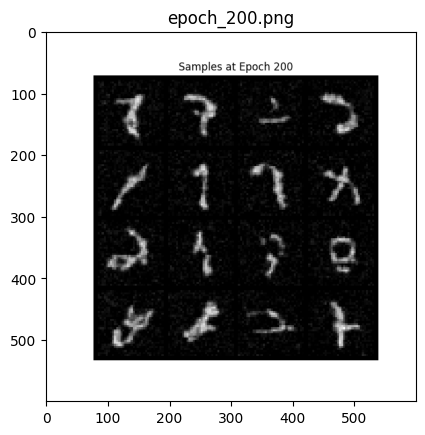

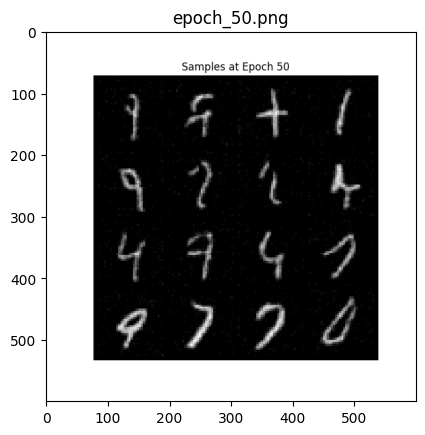

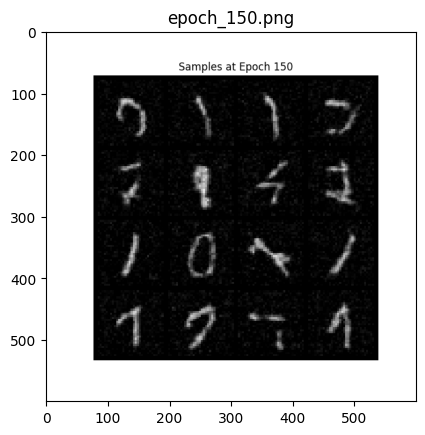

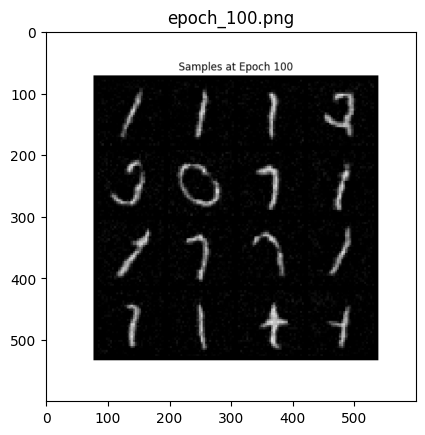

In [10]:
for img in glob('/kaggle/working/generated/*.png'):
    image = plt.imread(img)
    plt.imshow(image)
    plt.title(img.split("generated")[-1][1:])
    plt.show()

In [11]:
def sample_from_text(model, text_embedder, label_id, n_samples=8):
    model.eval()
    with torch.no_grad():
        x = torch.randn((n_samples, 1, 32, 32)).to(device)
        label_tensor = torch.full((n_samples,), label_id, device=device)
        text_emb = text_embedder(label_tensor)

        for t_step in reversed(range(T)):
            t = torch.full((n_samples,), t_step, device=device)
            pred = model(x, t, text_emb)
            alpha = alphas[t_step].to(device)
            alpha_bar = alphas_cumprod[t_step].to(device)
            beta = betas[t_step].to(device)

            x = (1 / torch.sqrt(alpha)) * (x - (1 - alpha) / torch.sqrt(1 - alpha_bar) * pred)
            if t_step > 0:
                x += torch.sqrt(beta) * torch.randn_like(x)
        x = torch.clamp((x + 1) / 2, 0, 1)
    return x


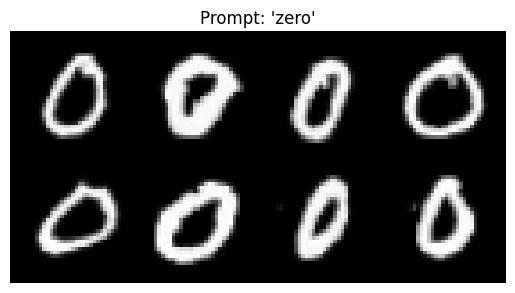

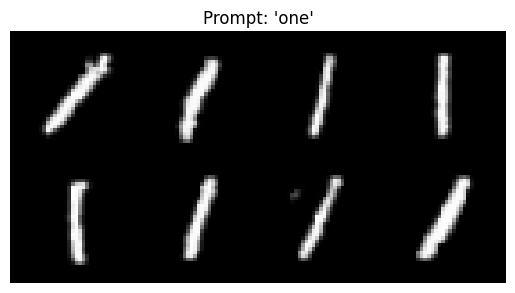

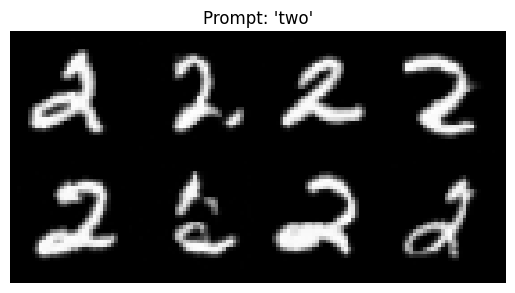

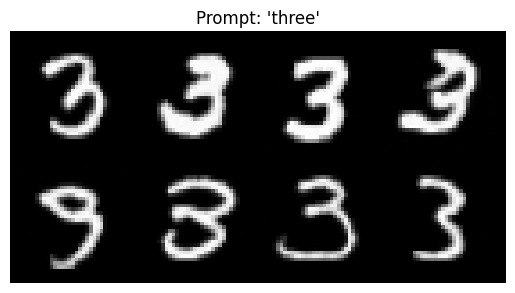

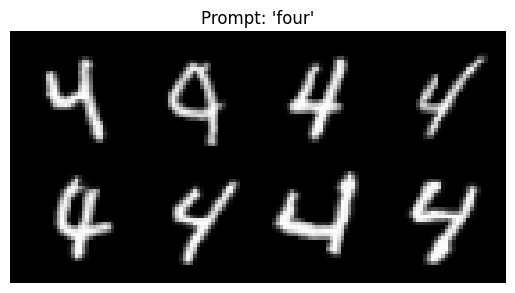

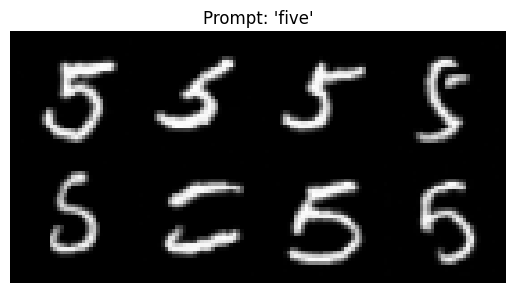

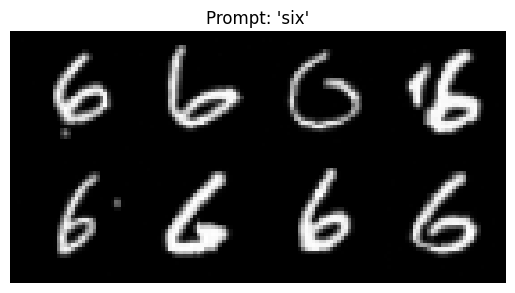

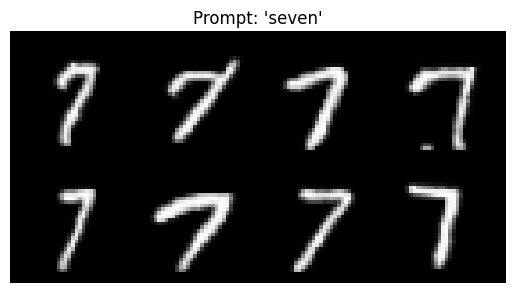

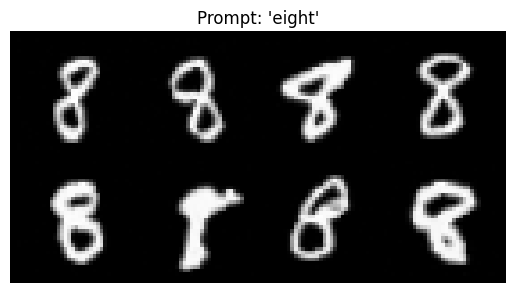

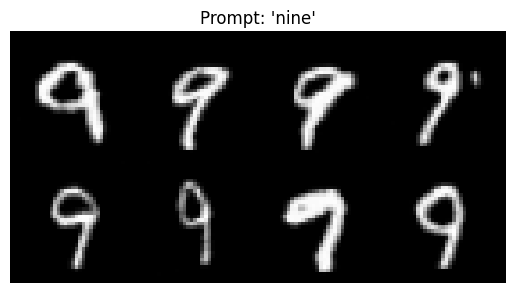

In [12]:
for digit_name, idx in zip(label_to_text, range(10)):
    imgs = sample_from_text(model, text_embedder, label_id=idx)
    grid = utils.make_grid(imgs, nrow=4)
    plt.imshow(grid.permute(1, 2, 0).cpu().numpy())
    plt.title(f"Prompt: '{digit_name}'")
    plt.axis("off")
    plt.show()